In [9]:
from data_l63_v1 import create_and_save_dataset,generate_l63_dataset
import matplotlib.pyplot as plt
import numpy as np


In [10]:

# ---------- EASY: well-separated modes, small overlap ----------
# Target rhos near classic L63 but separated:
#   Mode A:  ρ ≈ 24  (θ1+θ2 = 48)
#   Mode B:  ρ ≈ 32  (θ1+θ2 = 64)
mus_L_easy = [
    [26.0, 22.0, 10.0, 8/3, 0.0],   # [θ1, θ2, θ3(=σ), θ4(=β), θ5(dummy)]
    [34.0, 30.0, 15.0, 3.5, 0.0],
]
covs_L_easy = [
    np.diag([1.5**2, 1.5**2, 1.0**2, 0.3**2, 1.0**2]),
    np.diag([1.5**2, 1.5**2, 1.0**2, 0.3**2, 1.0**2]),
]
weights_L_easy = [0.2, 0.8]

# ---------- INTERMEDIATE: some overlap, larger std on θ1,θ2 ----------
# Closer means + bigger stds:
#   Mode A:  ρ ≈ 26  (θ1+θ2 = 52)
#   Mode B:  ρ ≈ 30  (θ1+θ2 = 60)
mus_L_inter = [
    [28.0, 24.0, 10.5, 3.2, 0.0],   # ρ ≈ 26
    [31.0, 29.0, 14.5, 3.3, 0.0],   # ρ ≈ 30
]
covs_L_inter = [
    np.diag([3.5**2, 3.5**2, 1.2**2, 0.35**2, 1.0**2]),
    np.diag([3.5**2, 3.5**2, 1.2**2, 0.35**2, 1.0**2]),
]
weights_L_inter = [0.2, 0.8]


# ---------- HARD: mirror modes with identical sum (exchangeable) ----------
# Both modes have (theta1+theta2/2) = 30 (e.g., 22+8 and 8+22), same σ and β.
# Large std on θ1,θ2 makes it hard to tell θ1 vs θ2; diagonal only (no corr).
mus_L_hard = [
    [40.0,  16.0, 12.0, 3.2, 0.0],   # rho = 30 (or 15 if you halve later)
    [ 16.0, 40.0, 12.0, 3.2, 0.0],
]
covs_L_hard = [
    np.diag([5.0**2, 5.0**2, 1.0**2, 0.3**2, 1.0**2]),
    np.diag([5.0**2, 5.0**2, 1.0**2, 0.3**2, 1.0**2]),
]
weights_L_hard = [0.2, 0.8]

# ---------- choose a case and generate ----------
dt_subsample = 1
T_window = 1000

# EXAMPLE: use the HARD case (swap to *_easy or *_inter as needed)
mus_L   = mus_L_hard
covs_L  = covs_L_hard
weights_L = weights_L_hard

all_cases = {
    # "easy": (mus_L_easy, covs_L_easy, weights_L_easy),
            "intermediate": (mus_L_inter, covs_L_inter, weights_L_inter),
            "hard": (mus_L_hard, covs_L_hard, weights_L_hard)}
# for case, (mus_L, covs_L, weights_L) in all_cases.items():
#     print (f"Generating case: {case}")
#     create_and_save_dataset(
#         save_path=f"./data/l63_LATENT_GMM_dt{dt_subsample}_T{T_window}_w28_{case}.npz",
#         prior_type="latent_mixture_gaussian",
#         mus_L=mus_L,
#         covs_L=covs_L,
#         weights_L=weights_L,
#         N_params=256,
#         N_traj_per_param=200,
#         dt_subsample=dt_subsample,
#         T_window=T_window,
#         avg = False,
#         clip_physical=False,   # keep true latent geometry -> mapped (σ,ρ,β)
#         save_physical=False
# )


In [21]:
theta, trajectories = generate_l63_dataset(
    prior_type="latent_mixture_gaussian",
    N_params=1000,
    N_traj_per_param=1,
    T_window=10,
    dt=0.01,
    discard_time=10.0,
    sigma_range=(5, 20),
    rho_range=(27.7,28.2),
    beta_range=(2.6, 2.7),
    
    # latent-space prior controls
    mus_L=mus_L,
    covs_L=covs_L,
    weights_L=weights_L,
    # control clipping of physical parameters after mapping
    clip_physical=False,
    # NEW: optionally also return physical (sigma,rho,beta) for sanity checks
    return_physical=False,
)

In [23]:
theta_3.shape, trajectories.shape

((1000, 3), (1000, 10, 3))

In [22]:
theta_3 = np.concatenate([
                theta[:, [0, 1]].mean(axis=1, keepdims=True),  # Average theta1 and theta2
                theta[:, [2, 3]]  # Keep theta3 and theta4
            ], axis=1)

(array([ 3.,  5.,  1.,  4.,  9., 10., 17., 28., 38., 53., 44., 87., 72.,
        68., 70., 78., 98., 83., 50., 46., 40., 23., 22., 22., 11.,  8.,
         7.,  0.,  1.,  2.]),
 array([17.10838174, 17.84625926, 18.58413678, 19.3220143 , 20.05989182,
        20.79776934, 21.53564686, 22.27352438, 23.0114019 , 23.74927942,
        24.48715693, 25.22503445, 25.96291197, 26.70078949, 27.43866701,
        28.17654453, 28.91442205, 29.65229957, 30.39017709, 31.12805461,
        31.86593213, 32.60380965, 33.34168716, 34.07956468, 34.8174422 ,
        35.55531972, 36.29319724, 37.03107476, 37.76895228, 38.5068298 ,
        39.24470732]),
 <BarContainer object of 30 artists>)

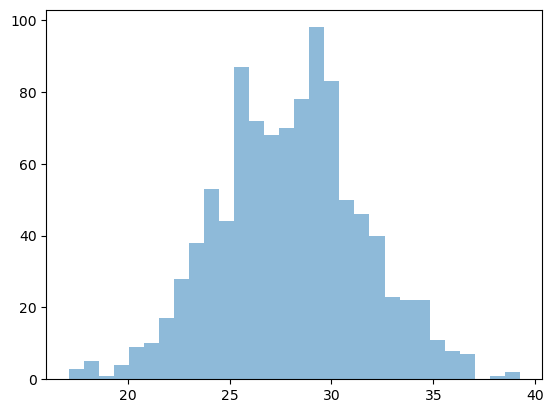

In [24]:
plt.hist(theta_3[:,0], bins=30, alpha=0.5, label='theta1+theta2')

array([[ 1.        , -0.06423054],
       [-0.06423054,  1.        ]])

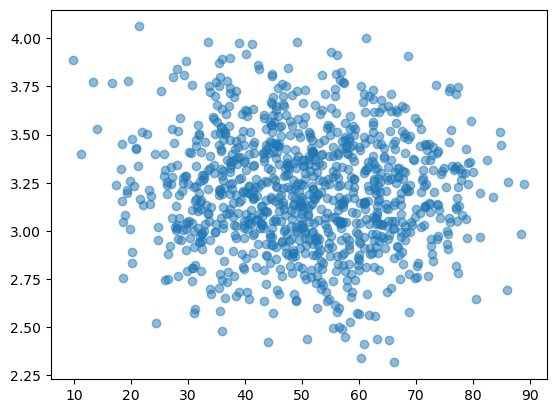

In [58]:
pm = 2
var = 2
x2 = np.mean(trajectories[:,:,var], axis=1)  # Average over time dimension
plt.scatter(x2, theta_3[:,pm], alpha=0.5)
np.corrcoef(x2, theta_3[:,pm])

In [2]:
# import xarray as xr
ds= np.load("./data/l63_LATENT_GMM_dt1_T1000_w28_intermediate.npz")

In [4]:
params_train = ds["theta_train"]   # (N_train, 3) -> [sigma, rho, beta]
trajs_train  = ds["trajs_train"] 
trajs_train.shape

(40960, 1000, 3)

<module 'matplotlib.pyplot' from '/Users/ss18284/miniconda3/envs/ml_nflow/lib/python3.11/site-packages/matplotlib/pyplot.py'>

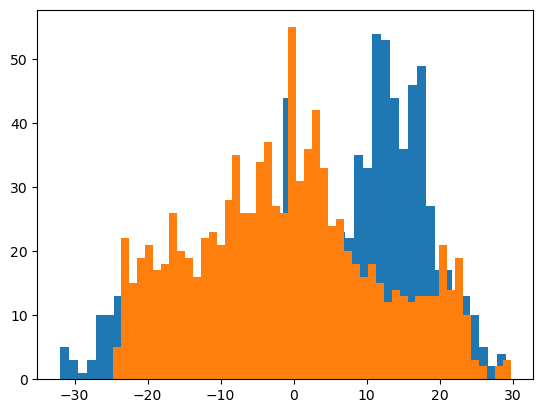

In [7]:
plt.hist(ds["trajs_train"][0,:,0],bins=50)
plt.hist(ds["trajs_train"][1,:,0],bins=50)
plt

In [3]:
plt.scatter(trajs_train[1001,:,0], trajs_train[1001,:,1])
plt.scatter(trajs_train[1000,:50,0], trajs_train[1000,:50,1])
plt.scatter(trajs_train[1000,:20,0], trajs_train[1000,:20,1])



NameError: name 'trajs_train' is not defined

# Data generation for L96

In [70]:
from l96_data_generation import create_and_save_dataset

# Define Gaussian prior parameters
# Parameters: [F, h, c, b]
mu = np.array([12.0, 1.0, 10.0, 10.0])

# Covariance matrix (4x4)
cov = np.array([
    [5.0,  0.0,  0.0,  0.0],   # var(F) = 5^2
    [ 0.0,  0.16, 0.0,  0.0],   # var(h) = 0.4^2
    [ 0.0,  0.0,  4.0,  0.0],   # var(c) = 2^2
    [ 0.0,  0.0,  0.0,  1.0]    # var(b) = 1^2
])

print("="*60)
print("Generating L96 Dataset with Gaussian Prior")
print("="*60)
print(f"Prior mean: {mu}")
print(f"Prior std:  {np.sqrt(np.diag(cov))}")
print()

# Generate and save dataset
create_and_save_dataset(
    save_path='./data/l96_gaussian_dataset_dt1_T500.npz',
    prior_type='gaussian',
    N_params=256,           # Number of parameter sets
    N_traj_per_param=200,    # Trajectories per parameter set
    T_window=500,          # Time steps to save
    dt_subsample=1,         # Subsample every 5 steps
    test_split=0.2,
    K=8,                    # 8 slow variables
    J=8,                    # 8 fast variables per slow variable
    F_range=(10, 15),
    h_range=(0.5, 2.0),
    c_range=(5, 15),
    b_range=(8, 12),
    mu=mu,
    cov=cov,
    clip=True,              # Clip samples to ranges
    avg=False,
    seed=42
)


Generating L96 Dataset with Gaussian Prior
Prior mean: [12.  1. 10. 10.]
Prior std:  [2.23606798 0.4        2.         1.        ]

Dataset saved to ./data/l96_gaussian_dataset_dt1_T500.npz
  Training samples: 40960
  Test samples: 10240
  X shape: (40960, 500, 8), Y shape: (40960, 500, 64)
  Parameters shape: (40960, 4)


In [1]:
import numpy as np
ds= np.load("./data/l96_gaussian_dataset_dt1_T500.npz")


(40960, 4)

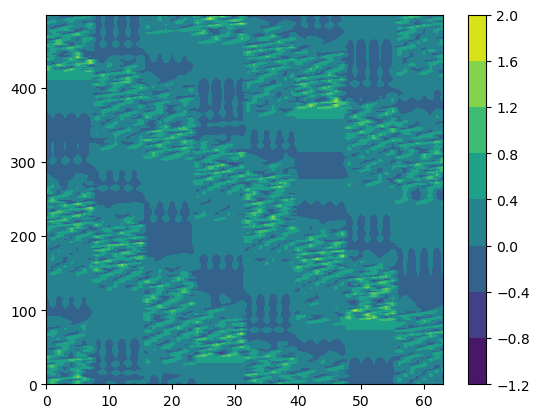

In [3]:
import matplotlib.pyplot as plt
plt.contourf(ds['Y_train'][0,:,:])
plt.colorbar()
ds['params_train'].shape

(40960, 4)

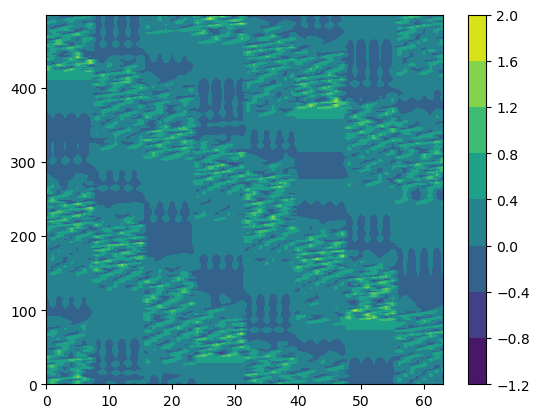

In [7]:
plt.contourf(ds['Y_train'][0,:,:])
plt.colorbar()
ds['params_train'].shape

(array([10.78272322,  1.18784901, 10.22184518,  8.84900642]),
 array([12.4670332 ,  1.09843062,  6.08065975,  8.67181395]))

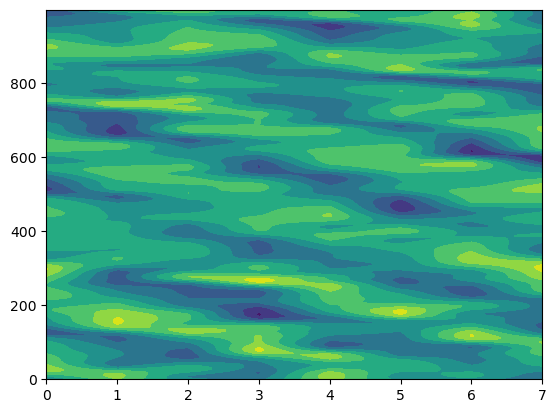

In [68]:
plt.contourf(ds['X_train'][15,:,:] - ds['X_train'][10,:,:])
ds['params_train'][15,:],ds['params_train'][10,:], 

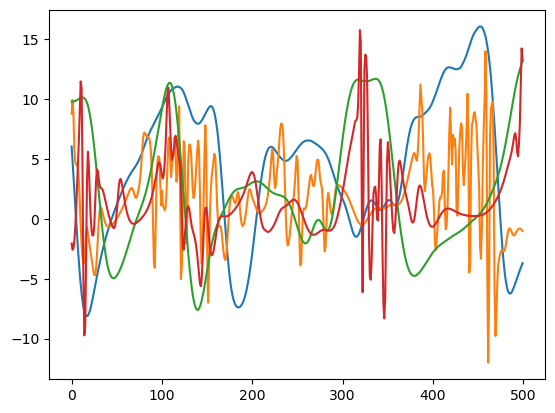

In [16]:
sample= 200
h = ds['params_train'][sample, 1]
c = ds['params_train'][sample, 2]
b = ds['params_train'][sample, 3]
plt.plot( h*c/b * ds['X_train'][sample,0:500,0])
plt.plot(c * ds['Y_train'][sample,0:500,0])

sample= 2000

plt.plot( h*c/b * ds['X_train'][sample,0:500,0])
plt.plot(c * ds['Y_train'][sample,0:500,0])

# plt.plot( ds['X_train'][sample,0:500,0])


In [6]:
ys_2 =  ds['Y_train'][:,300,:]
h_param = ds['params_train'][:,1]

In [12]:

c_param = ds['params_train'][:,2]
b_param = ds['params_train'][:,3]


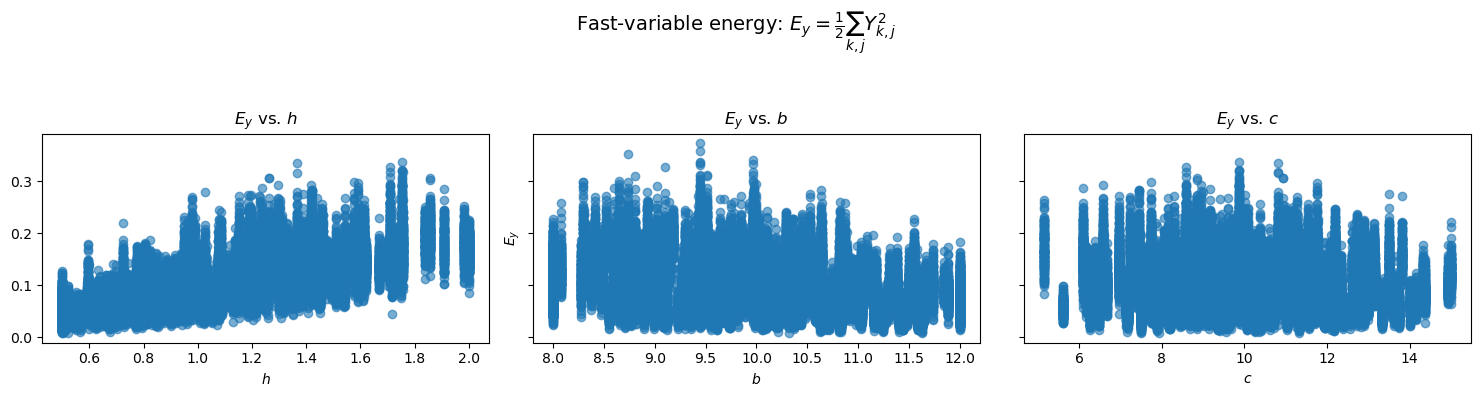

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# 1) Energy vs b
axes[1].scatter(b_param, ys_energy, alpha=0.6)
axes[1].set_xlabel(r'$b$')
axes[1].set_ylabel(r'$E_y$')
axes[1].set_title(r'$E_y$ vs. $b$')

# 2) Energy vs h
axes[0].scatter(h_param, ys2_energy, alpha=0.6)
axes[0].set_xlabel(r'$h$')
axes[0].set_title(r'$E_y$ vs. $h$')

# 3) Energy vs c
axes[2].scatter(c_param, ys2_energy, alpha=0.6)
axes[2].set_xlabel(r'$c$')
axes[2].set_title(r'$E_y$ vs. $c$')

# Suptitle with the energy formula
fig.suptitle(
    r'Fast-variable energy: $E_y = \frac{1}{2}\sum_{k,j} Y_{k,j}^2$',
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


In [15]:
np.corrcoef(h_param, ys2_energy)

array([[1.        , 0.74426445],
       [0.74426445, 1.        ]])

In [25]:
from tqdm import tqdm
def est_corr_time(y_t):
    """
    y_t: 1D time series (for one (k,j) or spatially averaged).
    returns e-folding correlation time in model time units.
    """
    y = y_t - np.mean(y_t)
    acf = np.correlate(y, y, mode='full')
    acf = acf[acf.size // 2:]
    acf /= acf[0]  # normalize

    # find first lag where acf < 1/e
    idx = np.where(acf < 1/np.e)[0]
    if len(idx) == 0:
        return np.nan
    return idx[0]  # if dt=1; multiply by dt otherwise

acf_times = []
for sample in tqdm (range(5)):
    y_t = ds['Y_train'][10*sample+1000, :500, 0]  # first fast variable
    tau = est_corr_time(y_t)
    acf_times.append(tau)

100%|██████████| 5/5 [03:00<00:00, 36.14s/it]


In [49]:
xs_2 =  ds['X_train'][:4000,:,:]
ys_2 =  ds['Y_train'][:4000,:,:]

h_param = ds['params_train'][:4000,:]

In [50]:
x_energy = np.sum(xs_2, axis=(2)) / 2
y_energy = np.sum(ys_2, axis=(2)) / 2


In [48]:
np.corrcoef(np.mean(x_energy[:,:500],axis = 1), h_param[:,2])

array([[ 1.        , -0.03136205],
       [-0.03136205,  1.        ]])

In [53]:
np.corrcoef(np.mean(y_energy[:,:100],axis = 1), h_param[:,2])


array([[1.        , 0.03876893],
       [0.03876893, 1.        ]])